DX703 - Final project - Milestone 1
=============

<div style="background: linear-gradient(180deg, #2a333d 0%, #9ec9fd 98%)
; color: #ffffff; padding: 60px 40px
; font-family: 'Playfair Display', Georgia, serif; border-radius: 8px
;">

  <!--_ subheader_tag _-->
  <div style="font-family: -apple-system, BlinkMacSystemFont, sans-serif; font-size: 11px; font-weight: 700; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 20px; color: rgba(255, 255, 255, 0.85)
  ;">
    <span style="color: #ffd028; margin-right: 6px;">●</span> DX703 —
  </div>

  <!--_ display_headline _-->
  <h1 style="margin: 0; font-size: 56px; line-height: 1.1; font-weight: 500;">
    <span style="color: #ffd028; font-weight: 700;">Milestone 1 </span><br> &#8212; Final Project    
    <span style="display: inline-block; vertical-align: middle; margin-right: 12px; background: #f1ede4; color: #222; font-family: monospace; font-size: 12px; padding: 8px 16px; border-radius: 20px; box-shadow: 0 4px 10px rgba(0,0,0,0.15);">
      ▶  NLP: HuffPost classification news
    </span></h1>





<style>
.todo {
    display: inline-block; 
    vertical-align: middle;
     margin-right: 12px; 
     background: #f0eadc; 
     color: #380303; 
     font-family: monospace; 
     font-size: 1em;      
     padding: 8px 16px; 
     border-radius: 20px; 
     box-shadow: 0 4px 10px rgba(0,0,0,0.15);
}
</style>




## Review of things to do

1. Choose dataset        
    - overview steps:
        - inspect 
            - count samples & target
            - example records
            - distributions
            - missing data
            - inconsistent data
            -  possible ambigous or overlapping data
        - Visualize
            - samples per label
            - text stats
            - duplicates, etc
            - word frequency plot/word cloud


    - <span class="todo"> graded questions </span>:
        1. *long text*: ----  describe the dataset
            - which data 
            - content.. samples
            - task decided to do
            - potential business use
        1. *long text*: ----  initial observation
            - imblanaced?
            - patterns
            - anomalies
            - redundancies
            - topic overlap
        1. *long text*: ----  challenges
            - affecting model performance?
        1. *long text*: ----  planning what to do
        1. *long text*: ----  why this dataset?


2. Problem framing
    - steps:
        - diagnose challenges 
            - class imabalance
            - lenght variances
            - noise
            - leakage
            - overlapping labels
            - processing constraint/time
        - map what to do
        - explore metrics
            - primary
            - secondary (precission-recall, confusion)
            - protocol, seed
    
    - <span class="todo"> graded questions </span>:
        1. *long text*: ----  one sentence of research question
        1. *long text*: ----  input vs output
        1. *long text*: ----  research question on issues
        1. *long text*: ----  in depth tehcniuqes to use for working on the issues
        1. *long text*: ----  specify metrics

3. Data prep
    - steps:
        - load
        - cleaning
            - concat headline + summary
        - standardize
            - tokenize
            - max length
            - padding
        - process issues
        - reproducible split
        - documenting pipeline

    - <span class="todo"> graded questions </span>:
        1. *long text*: ----  describe the load & clean steps
        1. *long text*: ----  describe the preprocessing pipeline
        1. *long text*: ----  describe splitting & leakage prevention
        1. *long text*: ----  report counts, imbalance %, weighting, oversampling


4. First model
    - steps:
        - make baseline model
        - compile
        - train & validate
        - visualize

    - <span class="todo"> graded questions </span>:
        1. *long text*: ----  describe model architecture
        1. *long text*: ----  describe training - validation curve
        1. *long text*: ----  report validation metric
        1. *long text*: ----  reflection

5. Report GAIA
        
        

<div style="display: flex; 
     background: #fee500; 
     border-radius: 12px; 
     box-shadow: 0 2px 10px rgba(0,0,0,0.15);"  >
</div>



# CODE

In [1]:
import numpy                    as np
import pandas                   as pd
import matplotlib.pyplot        as plt
import seaborn                  as sns

from matplotlib.ticker          import StrMethodFormatter

import re


# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel



URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff_all = load_dataset("json", data_files=URL, split="train")

df = huff_all.to_pandas()






from IPython.display import display, HTML

def view_content(df):
    if isinstance(df, pd.Series):
        df = df.to_frame()

    with pd.option_context("display.max_colwidth", None):
        html = df.to_html(
            max_rows=None,
            max_cols=None,
            escape=True,
        )

    display(HTML(
        '<div style="width:100%; overflow-x:auto;">'
        '<style>'
        '.full-text-table td, .full-text-table th {'
        '    white-space:pre-wrap;'
        '    overflow-wrap:anywhere;'
        '    min-width:100px;'
        '    max-width:500px;'
        '    text-align:left;'
        '    vertical-align:top;'
        '}'
        '</style>'
        + html.replace('class="dataframe"', 'class="dataframe full-text-table"')
        + '</div>'
    ))


<div style="
    background: #140e36;
    color: white;
    padding: 22px 26px;
    border-radius: 8px;
    margin: 32px 0 20px 0;
    width: 80%
">
    <div style="color: #84ff00; font-size: .8em;">
        SECTION 01
    </div>
    <h2 style="color: white; margin: 8px 0; weight: 700"> EDA ----     </h2>
    <p style="color: #d6d0e4; margin: 0;">
    </p>
</div>

<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     01.1 </div>
    <div>
        <h3 style="margin: 0;"> Features inspection </h3>
        <small style="color: #777;">
            patterns, overlaps
        </small>
    </div>
</div>


<div style="
    display: flex;
    align-items: center;
    gap: 1px;
    margin: 24px 0 14px;
">
    <span style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 5px 12px;
        border-radius: 20px;
        font-size: 0.8EM;
        font-weight: 600;
    ">
        describe
    </span>

<h4 style="margin: 6px 0; color: #242424;">MISSINGNESS</h4>
</div>

In [2]:
df = (
    df
    .replace(r"^\s*$", pd.NA, regex=True)
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce"))
)

quality = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean().mul(100).round(4),
        "unique_values": df.nunique()
    })
    .sort_values("missing_pct", ascending=False)
)

quality

,dtype,missing,missing_pct,unique_values
authors,str,36620,18.2322,27992
short_description,str,19712,9.8141,178352
headline,str,6,0.0030,199343
category,str,0,0.0000,41
link,str,0,0.0000,200812
date,datetime64[s],0,0.0000,2309


In [3]:
headline_less = len(df.query("headline.notna() and short_description.isna()"))

print(f""" total headline-less news: {headline_less}""")

print(f" % = {headline_less / len(df) * 100:.4f}%")



 total headline-less news: 19707
 % = 9.8117%



<div style="
    display: flex;
    align-items: center;
    gap: 1px;
    margin: 24px 0 14px;
">
    <span style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 5px 12px;
        border-radius: 20px;
        font-size: 0.8EM;
        font-weight: 600;
    ">
        describe
    </span>

<h4 style="margin: 6px 0; color: #242424;">DUPLICATES</h4>
</div>

In [4]:
duplicate_summary = pd.Series({
    "exact_duplicate_rows": df.duplicated().sum(),
    "repeated_nonmissing_links": df["link"].dropna().duplicated().sum(),
    "repeated_nonmissing_headlines": df["headline"].dropna().duplicated().sum()
})

duplicate_summary

exact_duplicate_rows               13
repeated_nonmissing_links          41
repeated_nonmissing_headlines    1504
dtype: int64

In [5]:

## _Keep headlines appearing on multiple calendar dates
df_duplicate_dates = (
    df
    .assign(date=lambda x: pd.to_datetime(x["date"], errors="coerce").dt.normalize())
    .dropna(subset=["headline", "date"])
    .assign(
        distinct_dates=lambda x: (
            x.groupby("headline")["date"].transform("nunique")
        )
    )
    .query("distinct_dates > 1")
    .sort_values(["headline", "date"])
)

## _Overall counts: unique headlines versus all matching rows
# display(
#     pd.Series({
#         "headlines_with_multiple_dates": df_duplicate_dates["headline"].nunique(),
#         "total_rows_for_these_headlines": len(df_duplicate_dates)
#     }).to_frame("count")
# )

## _Summary per headline
headline_summary = (
    df_duplicate_dates
    .groupby("headline", as_index=False)
    .agg(
        rows=("date", "size"),
        distinct_dates=("date", "nunique"),
        earliest_date=("date", "min"),
        latest_date=("date", "max")
    )
    .sort_values(["distinct_dates", "rows"], ascending=False)
)

display(headline_summary.head(10))

## _Show all records for five example headlines, not just the first five rows
example_headlines = headline_summary["headline"].head(5)

display(
    df_duplicate_dates
    .loc[lambda x: x["headline"].isin(example_headlines)]
    [["headline", "category", "date", "link"]]
)

,headline,rows,distinct_dates,earliest_date,latest_date
209,Sunday Roundup,90,89,2014-04-20,2016-07-24
214,The 20 Funniest Tweets From Women This Week,80,80,2015-04-25,2018-05-25
282,Weekly Roundup of eBay Vintage Clothing Finds ...,59,58,2012-02-03,2013-08-20
284,Weekly Roundup of eBay Vintage Home Finds (PHO...,54,54,2012-02-07,2013-08-26
270,Watch The Top 9 YouTube Videos Of The Week,46,46,2012-01-28,2013-02-02
227,The Funniest Tweets From Parents This Week,41,41,2014-04-20,2018-01-19
38,Animal Photos Of The Week,36,36,2012-01-29,2014-04-06
49,Best Parenting Tweets: What Moms And Dads Said...,33,33,2012-07-09,2014-04-13
228,The Funniest Tweets From Women This Week,33,33,2014-04-26,2015-03-21
78,Extreme Weather Photos Of The Week,29,29,2013-03-24,2014-02-09


,headline,category,date,link
124780,Sunday Roundup,POLITICS,2014-04-20,https://www.huffingtonpost.com/entry/sunday-ro...
124201,Sunday Roundup,POLITICS,2014-04-27,https://www.huffingtonpost.com/entry/sunday-ro...
123653,Sunday Roundup,POLITICS,2014-05-04,https://www.huffingtonpost.com/entry/sunday-ro...
123094,Sunday Roundup,POLITICS,2014-05-11,https://www.huffingtonpost.com/entry/sunday-ro...
122492,Sunday Roundup,POLITICS,2014-05-18,https://www.huffingtonpost.com/entry/sunday-ro...
...,...,...,...,...
152267,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-01,https://www.huffingtonpost.com/entry/weekly-ro...
151582,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-08,https://www.huffingtonpost.com/entry/weekly-ro...
150227,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-22,https://www.huffingtonpost.com/entry/weekly-ro...
149648,Weekly Roundup of eBay Vintage Home Finds (PHO...,HOME & LIVING,2013-07-29,https://www.huffingtonpost.com/entry/weekly-ro...


<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     01.2 </div>
    <div>
        <h3 style="margin: 0;"> Target inspection </h3>
        <small style="color: #777;">
            patterns, imbalance
        </small>
    </div>
</div>

In [6]:

target = "category"  # Change to "label" to analyze numeric labels instead

## _Treat blank categories as missing without modifying df
df_eda = (
    df
    .assign(**{
        target: lambda x: x[target].replace(r"^\s*$", pd.NA, regex=True)
    })
)

## _One reusable category summary
category_summary = (
    df_eda[target]
    .value_counts()
    .loc[lambda x: x > 0]
    .rename_axis(target)
    .reset_index(name="articles")
    .assign(
        pct=lambda x: x["articles"].div(x["articles"].sum()).mul(100),
        cumulative_pct=lambda x: x["pct"].cumsum(),
        fewer_than_10=lambda x: x["articles"] < 10
    )
)

display(category_summary.round(2))

## _Rare categories; an empty result means none meet this threshold
display(category_summary.query("articles < 10"))

## _Largest and smallest categories
display(category_summary.head(5))
display(category_summary.tail(5).sort_values("articles"))

,category,articles,pct,cumulative_pct,fewer_than_10
0,POLITICS,32739,16.30,16.30,False
1,WELLNESS,17827,8.88,25.18,False
2,ENTERTAINMENT,16058,7.99,33.17,False
3,TRAVEL,9887,4.92,38.09,False
4,STYLE & BEAUTY,9649,4.80,42.90,False
5,PARENTING,8677,4.32,47.22,False
6,HEALTHY LIVING,6694,3.33,50.55,False
7,QUEER VOICES,6314,3.14,53.69,False
8,FOOD & DRINK,6226,3.10,56.79,False
9,BUSINESS,5937,2.96,59.75,False


,category,articles,pct,cumulative_pct,fewer_than_10


,category,articles,pct,cumulative_pct,fewer_than_10
0,POLITICS,32739,16.299981,16.299981,False
1,WELLNESS,17827,8.875645,25.175626,False
2,ENTERTAINMENT,16058,7.994902,33.170528,False
3,TRAVEL,9887,4.922506,38.093033,False
4,STYLE & BEAUTY,9649,4.804011,42.897044,False


,category,articles,pct,cumulative_pct,fewer_than_10
40,EDUCATION,1004,0.499868,100.000000,False
39,CULTURE & ARTS,1030,0.512813,99.500132,False
38,LATINO VOICES,1129,0.562103,98.987319,False
37,COLLEGE,1144,0.569571,98.425216,False
36,ENVIRONMENT,1323,0.658691,97.855646,False


<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     01.1 </div>
    <div>
        <h3 style="margin: 0;"> Visualizations </h3>
        <small style="color: #777;">
            patterns, overlaps
        </small>
    </div>
</div>

In [7]:

## _Reusable visual style
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#E8E8E8",
        "text.color": "#333333",
        "axes.labelcolor": "#333333"
    }
)

## _Missing or blank text contributes zero words
df_plot = (
    df
    .assign(
        date=lambda x: pd.to_datetime(x["date"], errors="coerce"),
        category=lambda x: x["category"].replace(r"^\s*$", pd.NA, regex=True),
        headline_words=lambda x: (
            x["headline"].fillna("").str.split().str.len()
        ),
        description_words=lambda x: (
            x["short_description"].fillna("").str.split().str.len()
        )
    )
    .assign(
        year=lambda x: x["date"].dt.year.astype("Int64"),
        text_words=lambda x: x["headline_words"] + x["description_words"]
    )
)

## _Change this to headline_words or description_words if preferred
word_col = "text_words"
word_label = "Words in headline + short description"

word_summary = (
    df_plot
    .dropna(subset=["category"])
    .groupby("category", observed=True)
    .agg(
        articles=(word_col, "size"),
        mean_words=(word_col, "mean"),
        median_words=(word_col, "median")
    )
    .sort_values("mean_words", ascending=False)
)


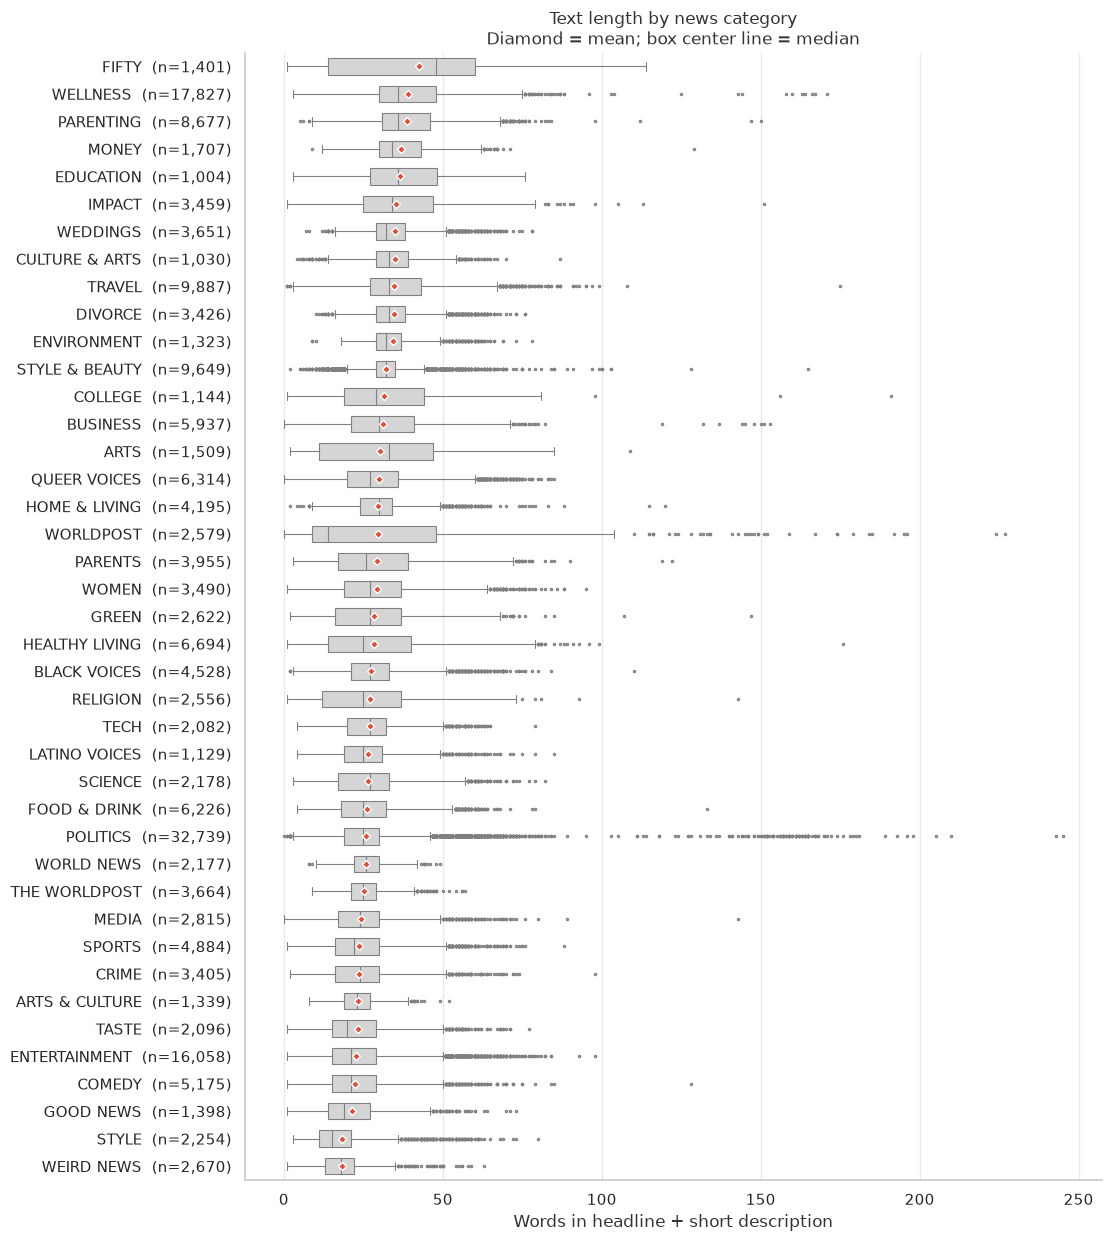

In [8]:

category_order = word_summary.index.tolist()

fig, ax = plt.subplots(
    figsize=(11, max(6, len(category_order) * 0.30)),
    layout="constrained"
)

sns.boxplot(
    data=df_plot,
    x=word_col,
    y="category",
    order=category_order,
    color="#D5D5D5",
    width=0.6,
    linewidth=0.8,
    fliersize=1.5,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#DD513A",
        "markeredgecolor": "white",
        "markersize": 4
    },
    ax=ax
)

ax.set_yticks(
    range(len(category_order)),
    labels=[
        f"{category}  (n={word_summary.loc[category, 'articles']:,})"
        for category in category_order
    ]
)

ax.set(
    title="Text length by news category\nDiamond = mean; box center line = median",
    xlabel=word_label,
    ylabel=""
)
ax.grid(axis="y", visible=False)

plt.show()

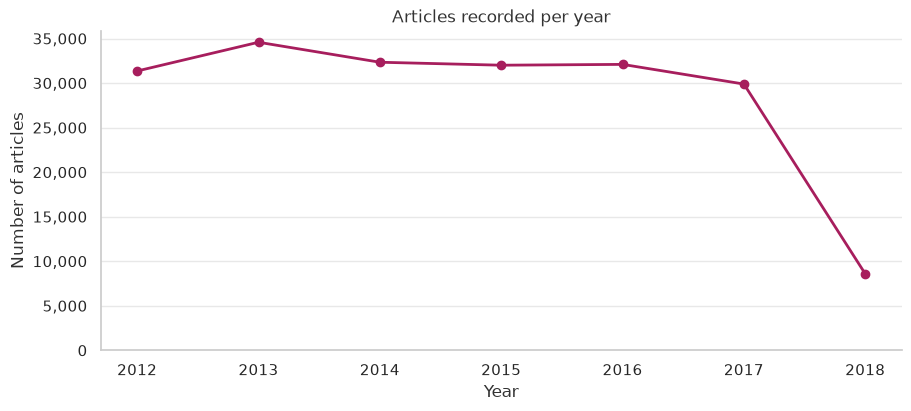

In [9]:
annual_counts = (
    df_plot
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .rename("articles")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.plot(
    annual_counts["year"].to_numpy(dtype=int),
    annual_counts["articles"],
    color="#A71E5D",
    marker="o",
    linewidth=2
)

ax.set(
    title="Articles recorded per year",
    xlabel="Year",
    ylabel="Number of articles",
    ylim=(0, None)
)
ax.set_xticks(annual_counts["year"].to_numpy(dtype=int))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)

plt.show()

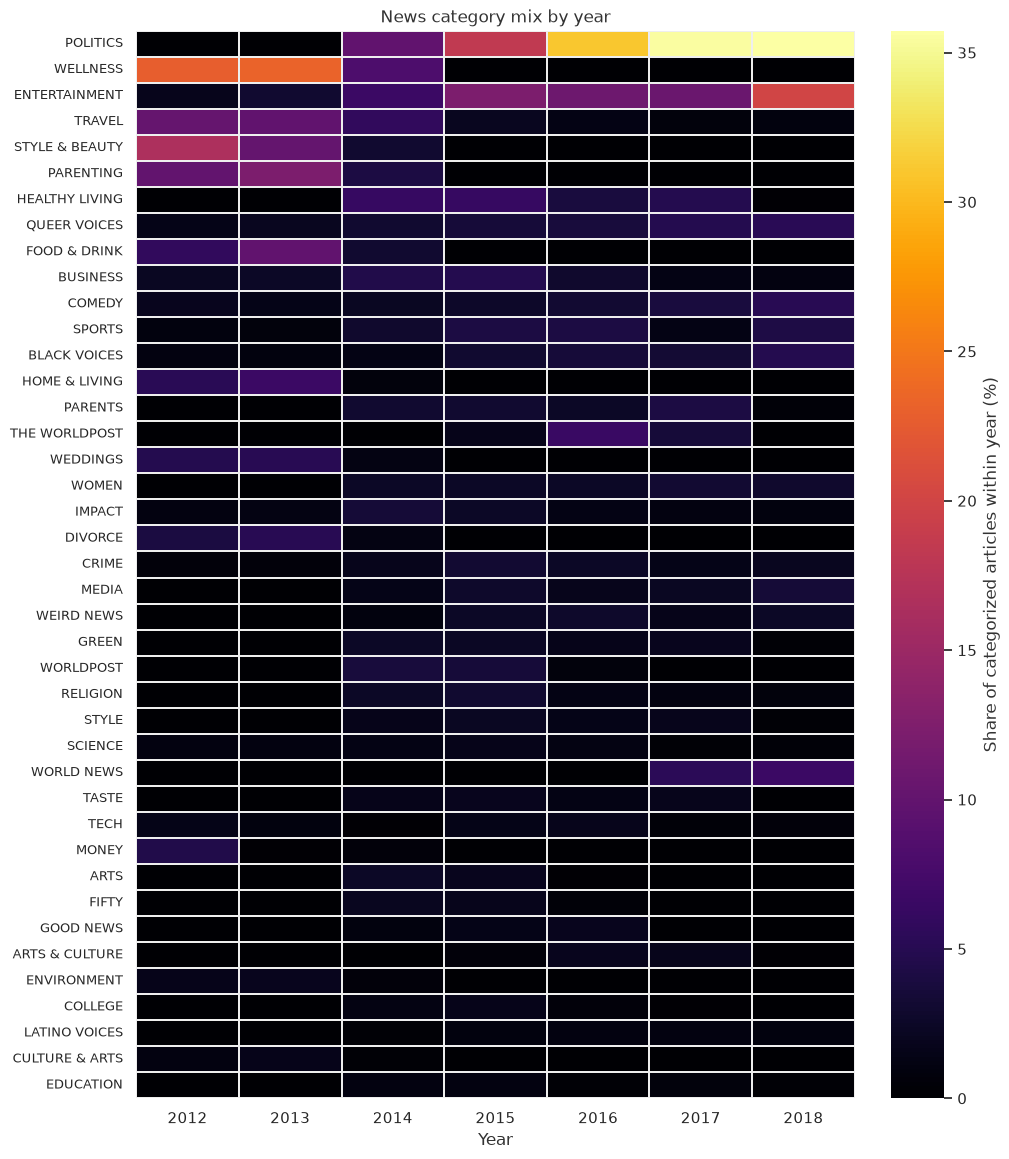

In [10]:
category_year_counts = (
    pd.crosstab(
        index=df_plot["category"],
        columns=df_plot["year"]
    )
    .reindex(category_order, fill_value=0)
)

category_year_pct = (
    category_year_counts
    .div(category_year_counts.sum(axis=0), axis="columns")
    .mul(100)
)

## _Order categories by total article count
heatmap_order = (
    category_year_counts
    .sum(axis=1)
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(
    figsize=(10, max(6, len(heatmap_order) * 0.28)),
    layout="constrained"
)

sns.heatmap(
    category_year_pct.loc[heatmap_order],
    cmap="inferno",
    vmin=0,
    linewidths=0.3,
    linecolor="#EEEEEE",
    yticklabels=True,
    cbar_kws={"label": "Share of categorized articles within year (%)"},
    ax=ax
)

ax.set(
    title="News category mix by year",
    xlabel="Year",
    ylabel=""
)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", labelsize=9)
ax.grid(False)

plt.show()

<div style="
    background: #140e36;
    color: white;
    padding: 22px 26px;
    border-radius: 8px;
    margin: 32px 0 20px 0;
    width: 80%
">
    <div style="color: #84ff00; font-size: .8em;">
        SECTION 03
    </div>
    <h2 style="color: white; margin: 8px 0; weight: 700"> PREPROCESSING ----     </h2>
    <p style="color: #d6d0e4; margin: 0;">
    </p>
</div>

<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     03.1 </div>
    <div>
        <h3 style="margin: 0;"> NEW INPUT COL </h3>
        <small style="color: #777;">
            make the input col, such as headline+description as well as headline+description+author_specialty
        </small>
    </div>
</div>

In [11]:
                
#      additional function - pulling authors' specialties       
# ======================================
####____◄ many authors have specialties that they most likely write one category only... not sure if this is leakage prone

possible_markers_for_specialty = ['contributor', 'author', 'specialist']
extra_words_to_replace = ['editor', 'author']

def _build_pattern(words: list, whole_word: bool = False) -> str:
    ## __Join words into one regex pattern
    joined = "|".join(re.escape(w) for w in words if w)
    if not joined:
        return ""
    return rf"\b(?:{joined})\b" if whole_word else joined


def pull_author_specialty(
    author,
    marker: list = possible_markers_for_specialty,
    extra_words: list = extra_words_to_replace,
) -> str:
    ## __Return "" for missing or non-text input
    if not isinstance(author, str):
        return ""

    ## __Return "" when no marker pattern exists
    pattern_marker = _build_pattern(marker)
    if not pattern_marker:
        return ""

    ## __Match the first marker, ignoring capitalization
    match = re.search(pattern_marker, author, flags=re.IGNORECASE)
    if match is None:
        return ""

    ## __Extract text after the marker and convert literal \n to a space
    specialty = author[match.end():].replace("\\n", " ")

    ## __Remove unwanted words, if any were provided
    pattern_after = _build_pattern(extra_words, whole_word=True)
    if pattern_after:
        specialty = re.sub(pattern_after, "", specialty, flags=re.IGNORECASE)

    ## __Normalize spaces and trim punctuation
    specialty = " ".join(specialty.split()).strip(",:;- ")

    return specialty


In [12]:
                
#       make function      
# ======================================
# 

def combining_news_text(df)->pd.DataFrame:
    return (
        df 
        .assign(
            cleaned_headline = lambda x: (
                x["headline"] 
                .fillna("")                     ####____◄ make any NA to be empty... not that needed
                .astype("string")               ####____◄ 
                .str.replace(r"\s+", " ", regex = True)     ####____◄ just fixing escape code
                .str.strip()
            ),

            cleaned_content = lambda x: (
                x["short_description"]
                .fillna("") 
                .astype("string")
                .str.replace(r"\s+", " ", regex = True)
                .str.strip()
            ),

            author_spec = lambda x: (
                x['authors']
                .apply(pull_author_specialty)
            )
        )

        .assign(
            combo_text_H_C_     = lambda x: (
                            x["cleaned_headline"] + "\n" + x["cleaned_content"]
                            ).str.strip()
                ,
            combo_text_H_C_A_   = lambda x: (
                            x["cleaned_headline"] + "\n" + x["cleaned_content"] + "\n" + x["author_spec"]
                            ).str.strip()
        )
    )

In [13]:
df_textmerged = (
    df 
    .pipe(combining_news_text)
    .query("combo_text_H_C_ != '' ")
    .dropna(subset = ['category'])
)

In [14]:
df_textmerged.sample(10)[["category", "authors", "short_description", "combo_text_H_C_", "combo_text_H_C_A_"]]

,category,authors,short_description,combo_text_H_C_,combo_text_H_C_A_
54454,THE WORLDPOST,"Alistair Smout, Reuters","""We can prevent Brexit by refusing to accept t...",Thousands March For Europe In London Brexit Pr...,Thousands March For Europe In London Brexit Pr...
1748,ENTERTAINMENT,Jenna Amatulli,The rapper was sentenced to two to four years ...,"Meek Mill Released From Prison, Looks Forward ...","Meek Mill Released From Prison, Looks Forward ..."
96968,TASTE,"Epicurious, ContributorThe most trusted, autho...",Shopping for eggs? Better bring a glossary.,Decoding The Secret Language Of Egg Cartons\nS...,Decoding The Secret Language Of Egg Cartons\nS...
109331,WORLDPOST,"Vicky Kelberer, ContributorMA Candidate Pardee...",The success or failure of the open-ended Ameri...,The Silver-Lining of US Airstrikes in Syria\nT...,The Silver-Lining of US Airstrikes in Syria\nT...
109963,PARENTS,"Laurie Schacht, ContributorToy Insider Mom",It's clear that there are driving forces behin...,The Toy Giants\nIt's clear that there are driv...,The Toy Giants\nIt's clear that there are driv...
140130,FOOD & DRINK,"Maria Rodale, Contributor\nCEO and Chairman of...",Put the ingredients in a bowl and mix them up....,Syrian Salad\nPut the ingredients in a bowl an...,Syrian Salad\nPut the ingredients in a bowl an...
61000,POLITICS,Daniel Marans,"Warren wants him to stop whining about the ""sa...",Elizabeth Warren Calls Out Ted Cruz's Hypocris...,Elizabeth Warren Calls Out Ted Cruz's Hypocris...
90815,RELIGION,Alana Horowitz Satlin,NaN,Seton Hall University Priest Says He Was Fired...,Seton Hall University Priest Says He Was Fired...
9832,BUSINESS,"Yassmin Abdel-Magied, Guest WriterGuest Writer",And the price is often steepest for the women ...,Sexual Harassment Comes At A Cost. So Does Spe...,Sexual Harassment Comes At A Cost. So Does Spe...
107200,POLITICS,"Marlon Peterson, ContributorWriter and activis...","In 2014, where Blacks and Latinos are overwhel...",5.85 Million People Who Can't Vote But Can The...,5.85 Million People Who Can't Vote But Can The...



<div style="
    display: flex;
    align-items: center;
    gap: 1px;
    margin: 24px 0 14px;
">
    <span style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 5px 12px;
        border-radius: 20px;
        font-size: 0.8EM;
        font-weight: 600;
    ">
        review
    </span>

<h4 style="margin: 6px 0; color: #242424;">Conflicted text combo</h4>
</div>

In [15]:
conflicting_texts = (
    df_textmerged
    .groupby("combo_text_H_C_")["category"]
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

df_conflicts = (
    df_textmerged
    .loc[lambda x: x["combo_text_H_C_"].isin(conflicting_texts)]
    .sort_values(["combo_text_H_C_", "category"])
)



In [16]:
df_conflicts[["headline", "combo_text_H_C_", "category", "date"]].iloc[10:30]

,headline,combo_text_H_C_,category,date
63496,Is Prostitution Just Another Job?,Is Prostitution Just Another Job?\nChelsea Lan...,BUSINESS,2016-03-21
63382,Is Prostitution Just Another Job?,Is Prostitution Just Another Job?\nChelsea Lan...,WOMEN,2016-03-22
199543,"Kelly Rowland's Birthday: Singer Turns 31, Sty...","Kelly Rowland's Birthday: Singer Turns 31, Sty...",BLACK VOICES,2012-02-11
199508,"Kelly Rowland's Birthday: Singer Turns 31, Sty...","Kelly Rowland's Birthday: Singer Turns 31, Sty...",STYLE & BEAUTY,2012-02-11
114431,Marcia,Marcia,COMEDY,2014-08-18
118186,Marcia,Marcia,COMEDY,2014-07-07
114307,Marcia,Marcia,WOMEN,2014-08-19
121328,She's Baaaaack!,She's Baaaaack!,BLACK VOICES,2014-06-01
110816,She's Baaaaack!,She's Baaaaack!,COMEDY,2014-09-28
197992,Stylish Yellow Kitchen Accessories And Appliances,Stylish Yellow Kitchen Accessories And Applian...,FOOD & DRINK,2012-02-28


In [17]:
view_content(df.query("headline.str.contains('Sanders') and headline.str.contains('Sexist')"))

,category,headline,authors,link,short_description,date
9731,POLITICS,Sarah Huckabee Sanders Defends Trump's Sexist Attack On Kirsten Gillibrand,Marina Fang,https://www.huffingtonpost.com/entry/trump-attacks-kirsten-gillibrand_us_5a300bcfe4b07895028418cb,The president was widely criticized for a tweet suggesting the senator “would do anything” for campaign donations.,2017-12-12
58566,POLITICS,"Bernie Sanders Supporters Unleash Sexist, Nasty Attacks On Nevada's Dem Chair",Sam Stein,https://www.huffingtonpost.com/entry/bernie-sanders-nevada-dem-chair_us_573b4b8de4b0aee7b8e7dfa2,Just listen to the voicemails Roberta Lange has received.,2016-05-17
61991,POLITICS,The Sanders Campaign’s Sexist New Argument: Hillary Tries Too Hard,NaN,https://www.huffingtonpost.comhttp://nymag.com/thecut/2016/04/bernie-sanders-hillary-clinton-tries-too-hard-ambitious.html,"On Tuesday night, following Bernie Sanders’s big win in the Wisconsin primary, his campaign manager, Jeff Weaver, understandably",2016-04-07
61996,WOMEN,The Sanders Campaign’s Sexist New Argument: Hillary Tries Too Hard,NaN,https://www.huffingtonpost.comhttp://nymag.com/thecut/2016/04/bernie-sanders-hillary-clinton-tries-too-hard-ambitious.html,"On Tuesday night, following Bernie Sanders’s big win in the Wisconsin primary, his campaign manager, Jeff Weaver, understandably",2016-04-07
67277,POLITICS,Bernie Sanders Condemns Supporters' Sexist Comments About Hillary Clinton,Daniel Marans,https://www.huffingtonpost.com/entry/sanders-condemns-bernie-bros_us_56b75a28e4b08069c7a79b1e,"No tolerance for the ""Bernie Bros.""",2016-02-07


##### keep only the last

In [18]:
df_cleaned2 = (
    df_textmerged 
    .loc[lambda x: ~x["combo_text_H_C_"].isin(conflicting_texts)]
    .drop_duplicates(subset=["combo_text_H_C_"], keep="last")
    .reset_index(drop=True)
)

In [19]:
print(len(df_textmerged))
print(len(df_cleaned2))

200848
200350


<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     03.2 </div>
    <div>
        <h3 style="margin: 0;"> ANY LAST CLEANING </h3>
        <small style="color: #777;">
            no text, no label
        </small>
    </div>
</div>

In [20]:
(
    df_cleaned2 
    # .query("combo_text_H_C_A_ == ''")         ### none
    # .query("headline == '' or headline.isna()")  ### fine
    .query("category == '' or category.isna()")   ## none
)

,category,headline,authors,link,short_description,date,cleaned_headline,cleaned_content,author_spec,combo_text_H_C_,combo_text_H_C_A_


<div style="
    display: flex;
    align-items: center;
    gap: 0.5em;
    margin: 1em 0 0 0;
">
    <div style="
        background: #f3edf7;
        color: #7a0c7f;
        padding: 2em 2em;
        border-radius: 6px;
        font-weight: 600;
        width: 2em;
    "> 
     03.3 </div>
    <div>
        <h3 style="margin: 0;"> MERGE LABELS </h3>
        <small style="color: #777;">
            just combine those that are actually renamed
        </small>
    </div>
</div>

In [21]:
label_groups = {
    'ARTS & CULTURE'        :   [ 'ARTS', 'ARTS & CULTURE', 'CULTURE & ARTS'],
    'WORLD NEWS'            :   [ 'WORLDPOST','WORLD NEWS' ,'THE WORLDPOST'   ],
    'PARENTING'             :   [ 'PARENTS', 'PARENTING'   ],
    'STYLE & BEAUTY'        :   [ 'STYLE', 'STYLE & BEAUTY'   ],
    'FOOD & DRINK'          :   [ 'TASTE'  , 'FOOD & DRINK',   ],
    'ENVIRONMENT'           :   [ 'GREEN', 'ENVIRONMENT'   ],
    'WELLNESS'              :   [ 'HEALTHY LIVING' , 'WELLNESS'   ],  
}

## __Convert grouped labels into a lookup dictionary
label_mapping = {
    original: merged
    for merged, originals in label_groups.items()
    for original in originals
}

df_cleaned3 = (
    df_cleaned2
    .assign(
        cleaned_news_category = lambda x: (
            x["category"]
            .map(label_mapping)
            .fillna(x["category"])
        )
    )
)

In [22]:
view_content(df_cleaned3.sample(3)[["category", "cleaned_news_category", "combo_text_H_C_"]])

,category,cleaned_news_category,combo_text_H_C_
128805,WELLNESS,WELLNESS,"Lift Like a Girl: A Guide to Heavy Lifting\nLifting and building lean muscle have dozens of benefits for women. These benefits include: more defined muscles, stronger bones, injury prevention and increased calorie burn and fat loss."
126448,STYLE & BEAUTY,STYLE & BEAUTY,"Charlotte Casiraghi 'Drop It Like It's Hot' In Silver Chanel Couture Gown At The Rose Ball (PHOTOS)\nMaking her first official post-baby appearance at the Rose Ball in ﻿Monte-Carlo, Monaco on Saturday evening, Casiraghi joined"
152963,PARENTING,PARENTING,"Is Stress Hurting Your Relationship? What Can You Do About It?\nWhile raising a child with special needs, when it comes to keeping your relationship together and being in love, one of the most important insights is to recognize how stressful it is and how the stress can erode the best of relationships."


<div style="
    background: #140e36;
    color: white;
    padding: 22px 26px;
    border-radius: 8px;
    margin: 32px 0 20px 0;
    width: 80%
">
    <div style="color: #84ff00; font-size: .8em;">
        SECTION 03
    </div>
    <h2 style="color: white; margin: 8px 0; weight: 700"> SPLIT ----     </h2>
    <p style="color: #d6d0e4; margin: 0;">
    </p>
</div>

In [23]:
# df_model = df_cleaned3[["cleaned_news_category", "combo_text_H_C_", "combo_text_H_C_A_", "date"]].copy()
df_model = df_cleaned3.copy()

In [ ]:
stilldups = (
    df_model
    .groupby("combo_text_H_C_")['category']
    .nunique()
    .loc[lambda x: x > 1]
)

display(len(stilldups))
# display(stilldups.sample(2)) ## zero anyway

0

ValueError: a must be greater than 0 unless no samples are taken

In [24]:
len(df_model)

200350

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

text_input_col = "combo_text_H_C_"

## _Split 80% training and 20% temporary holdout
df_train, df_holdout = train_test_split(
    df_model,
    test_size=0.20,
    stratify=df_model["cleaned_news_category"],
    random_state=42
)

## _Divide the holdout equally: 10% validation and 10% test overall
df_val, df_test = train_test_split(
    df_holdout,
    test_size=0.50,
    stratify=df_holdout["cleaned_news_category"],
    random_state=42
)

## _Fit category-to-integer mapping on training labels only
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(df_train["cleaned_news_category"])
y_val = label_encoder.transform(df_val["cleaned_news_category"])
y_test = label_encoder.transform(df_test["cleaned_news_category"])

## _Raw text inputs; the attached KerasHub preprocessor handles tokenization
X_train = df_train[text_input_col].to_numpy(dtype=str)
X_val = df_val[text_input_col].to_numpy(dtype=str)
X_test = df_test[text_input_col].to_numpy(dtype=str)

num_classes = len(label_encoder.classes_)

## _Inspect split sizes and category proportions
split_sizes = pd.Series({
    "train": len(df_train),
    "validation": len(df_val),
    "test": len(df_test)
}).to_frame("articles")

split_category_pct = (
    pd.concat(
        {
            "train": df_train["cleaned_news_category"].value_counts(normalize=True),
            "validation": df_val["cleaned_news_category"].value_counts(normalize=True),
            "test": df_test["cleaned_news_category"].value_counts(normalize=True)
        },
        axis=1
    )
    .fillna(0)
    .mul(100)
    .round(2)
)

display(split_sizes)
display(split_category_pct)

,articles
train,160280
validation,20035
test,20035


,train,validation,test
cleaned_news_category,,,
POLITICS,16.33,16.33,16.33
WELLNESS,12.23,12.23,12.23
ENTERTAINMENT,8.01,8.02,8.01
PARENTING,6.26,6.26,6.26
STYLE & BEAUTY,5.87,5.87,5.86
TRAVEL,4.93,4.93,4.94
WORLD NEWS,4.20,4.20,4.20
FOOD & DRINK,4.15,4.15,4.15
QUEER VOICES,3.15,3.15,3.15


In [26]:
import keras_hub

## _Sample training data only; avoid tuning settings using the test set
df_sample = (
    df_train
    .sample(n=min(5_000, len(df_train)), random_state=42)
    .reset_index(drop=True)
)

tokenizer = keras_hub.models.DistilBertTokenizer.from_preset(
    "distil_bert_base_en_uncased"
)

## _Treat combined text as one input segment, matching your earlier setup
text_inputs = {
    "headline": df_sample["headline"].fillna("").astype(str),
    "headline_description": (
        df_sample["headline"].fillna("")
        + "\n"
        + df_sample["short_description"].fillna("")
    ).str.strip()
}

def get_token_lengths(text):
    tokens = tokenizer(text.to_numpy())

    if hasattr(tokens, "row_lengths"):
        return tokens.row_lengths().numpy()

    return [len(sequence) for sequence in tokens]


## _Include the 2 special tokens added later by the preprocessor
df_lengths = pd.DataFrame({
    name: get_token_lengths(text)
    for name, text in text_inputs.items()
}).add(2)

## _Token-length distribution
length_summary = (
    df_lengths
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95])
    .round(1)
)

## _Percentage of articles that would lose at least one token
truncation_pct = pd.DataFrame({
    limit: df_lengths.gt(limit).mean().mul(100)
    for limit in [64, 128, 256, 300, 512]
}).rename_axis(columns="sequence_length").round(2)

display(length_summary)
display(truncation_pct)

I0000 00:00:1794603376.874841    1247 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794603383.926540    1247 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6071 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2070 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


,headline,headline_description
count,5000.0,5000.0
mean,14.7,39.9
std,4.6,17.2
min,4.0,4.0
50%,15.0,38.0
75%,18.0,49.0
90%,21.0,62.1
95%,22.0,70.1
max,39.0,219.0


sequence_length,64,128,256,300,512
headline,0.00,0.00,0.0,0.0,0.0
headline_description,8.54,0.14,0.0,0.0,0.0


In [27]:

## _Treat combined text as one input segment, matching your earlier setup
text_inputs = {
    "headline": df_sample["headline"].fillna("").astype(str),
    "headline_description": df_sample["combo_text_H_C_"],
    "headline_desc_author": df_sample["combo_text_H_C_A_"]
}


## _Include the 2 special tokens added later by the preprocessor
df_lengths = pd.DataFrame({
    name: get_token_lengths(text)
    for name, text in text_inputs.items()
}).add(2)

## _Token-length distribution
length_summary = (
    df_lengths
    .describe(percentiles=[0.50, 0.75, 0.90, 0.95])
    .round(1)
)

## _Percentage of articles that would lose at least one token
truncation_pct = pd.DataFrame({
    limit: df_lengths.gt(limit).mean().mul(100)
    for limit in [64, 128, 256, 300, 512]
}).rename_axis(columns="sequence_length").round(2)

display(length_summary)
display(truncation_pct)

,headline,headline_description,headline_desc_author
count,5000.0,5000.0,5000.0
mean,14.7,39.9,43.1
std,4.6,17.2,20.1
min,4.0,4.0,5.0
50%,15.0,38.0,40.0
75%,18.0,49.0,53.0
90%,21.0,62.1,71.0
95%,22.0,70.1,81.0
max,39.0,219.0,219.0


sequence_length,64,128,256,300,512
headline,0.00,0.00,0.0,0.0,0.0
headline_description,8.54,0.14,0.0,0.0,0.0
headline_desc_author,15.42,0.14,0.0,0.0,0.0



end
=======================